In [2]:
import sys, os, distutils.core
sys.path.insert(0, os.path.abspath('./detectron2'))
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('./projects/Panoptic-DeepLab/'))
os.environ['DETECTRON2_DATASETS'] = '/home/liwa/data/datasets/'

from detectron2.data import DatasetCatalog, MetadataCatalog
# from oneformer.data.datasets.register_yeast_panoptic_annos_semseg import register_all_yeast_panoptic_annos_sem_seg

/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from run_notebooks.post_process_utils import get_largest_object, convert_to_rgb, segment_slide_window, segment_post_process
from skimage.io import imread, imsave

In [4]:
!pwd

/home/liwa/data/PytrochDeepyeast


In [5]:
from detectron2.config import get_cfg
from detectron2.projects.panoptic_deeplab import (
    PanopticDeeplabDatasetMapper,
    add_panoptic_deeplab_config,
)
from detectron2.engine import default_setup
from detectron2.engine import DefaultPredictor
from prediction import Predictor
from google.colab.patches import cv2_imshow
import os, json, cv2, random
from detectron2.utils.visualizer import Visualizer
import torch

In [6]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:8700m"
cfg = get_cfg()
add_panoptic_deeplab_config(cfg)
# add project-specific config (e.g., TensorMask) here if you're not running a model in detectron2's core library
cfg.merge_from_file("/home/liwa/data/PytrochDeepyeast/projects/Panoptic-DeepLab/configs/yeast_panoptics/config.yaml")

cfg.MODEL.DEVICE = "cuda:1"
# into cpu model
# cfg.MODEL.SEM_SEG_HEAD.NORM = "BN"
# cfg.MODEL.INS_EMBED_HEAD.NORM = "BN"
# cfg.MODEL.RESNETS.NORM = "BN"

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3 # set threshold for this model

# Find a model from detectron2's model zoo. You can use the https://dl.fbaipublicfiles... url as well
cfg.MODEL.WEIGHTS = os.path.abspath("/home/liwa/data/oneformer_output/output/model_0114999.pth")
# cfg.MODEL.WEIGHTS = "detectron2://DeepLab/R-52.pkl"
# cfg.INPUT.MIN_SIZE_TEST = 512
# cfg.INPUT.MAX_SIZE_TRAIN = 2048

In [7]:
from skimage.io import imread
import numpy as np

In [8]:
predictor = Predictor(cfg)

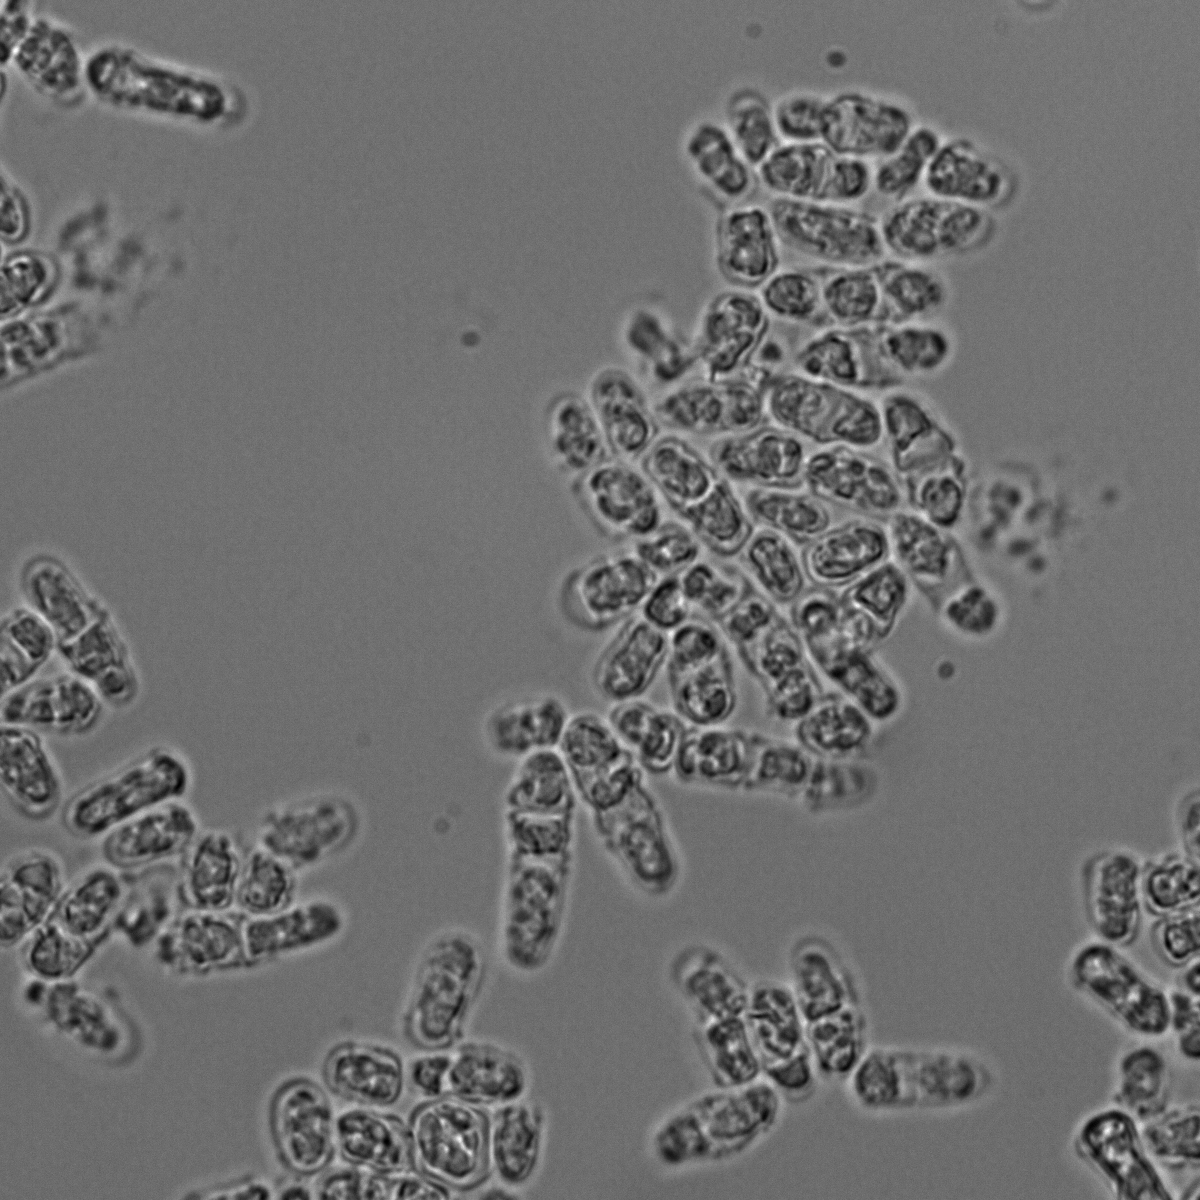

In [16]:
# im = cv2.imread("./00413.png")

im = imread("/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10093_leftImg8bit.png")[:,:,0]#[0:1024, 0:1024]
# image = image - image.min()
# image = image / image.max()
# image = (image * 255).astype(np.uint8)
# im = np.stack((image,)*3, axis=-1)
bigimage = convert_to_rgb(im)
cv2_imshow(bigimage)

In [17]:
# bigimage = np.zeros((512*4,512*4,3), dtype = np.uint8)
# for i in range(0, 4):
#     for j in range(0,4):
#         bigimage[i*512:(i+1)*512, j*512:(j+1)*512, :] = im
# cv2_imshow(bigimage)
# bigimage.shape


In [18]:
prediction_output = predictor(bigimage)
print(prediction_output.keys())


instances = prediction_output["instances"]
panoptic_seg, segments_info = prediction_output["panoptic_seg"]


scores = [1]+list(instances.scores.to("cpu"))
bboxes = instances.pred_boxes.to("cpu")
bboxes = [np.array([0,0,0,0])] + list(instances.pred_boxes.to("cpu"))

dict_keys(['sem_seg', 'center', 'offset', 'panoptic_seg', 'instances'])


In [19]:
segments_info = []
i=0
for panoptic_label in np.unique(panoptic_seg.to("cpu").numpy()):
    if panoptic_label == -1:
        # VOID region.
        continue
    pred_class = panoptic_label // 1000
    # isthing = pred_class in metadata.thing_dataset_id_to_contiguous_id.values()
    if i == 0:
        isthing = False
    else:
        isthing = True
    box = bboxes[i]
    segments_info.append(
        {
            "id": int(panoptic_label),
            "category_id": int(pred_class),
            "isthing": isthing,
            "score": float(scores[i]),
        }
    )
    i += 1

{0: {'id': 0, 'category_id': 0, 'isthing': False, 'score': 1.0}, 1001: {'id': 1001, 'category_id': 1, 'isthing': True, 'score': 0.051594849675893784}, 1002: {'id': 1002, 'category_id': 1, 'isthing': True, 'score': 0.810363233089447}, 1003: {'id': 1003, 'category_id': 1, 'isthing': True, 'score': 0.5995437502861023}, 1004: {'id': 1004, 'category_id': 1, 'isthing': True, 'score': 0.7648274302482605}, 2001: {'id': 2001, 'category_id': 2, 'isthing': True, 'score': 0.4666677713394165}, 2002: {'id': 2002, 'category_id': 2, 'isthing': True, 'score': 0.373782753944397}, 2003: {'id': 2003, 'category_id': 2, 'isthing': True, 'score': 0.07325192540884018}, 2004: {'id': 2004, 'category_id': 2, 'isthing': True, 'score': 0.42827561497688293}, 2005: {'id': 2005, 'category_id': 2, 'isthing': True, 'score': 0.9008157253265381}, 2006: {'id': 2006, 'category_id': 2, 'isthing': True, 'score': 0.7717667818069458}, 2007: {'id': 2007, 'category_id': 2, 'isthing': True, 'score': 0.6898882985115051}, 2008: {'i

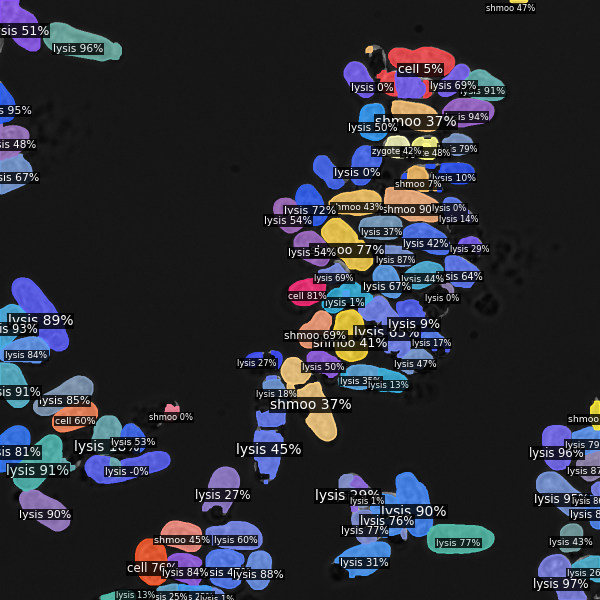

In [20]:
# panoptic_seg, segments_info = prediction_output["panoptic_seg"]
v = Visualizer(bigimage[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.5)
out = v.draw_panoptic_seg(panoptic_seg.to("cpu"), segments_info, area_threshold=20.0, alpha=0.8)
cv2_imshow(out.get_image()[:, :, ::-1])

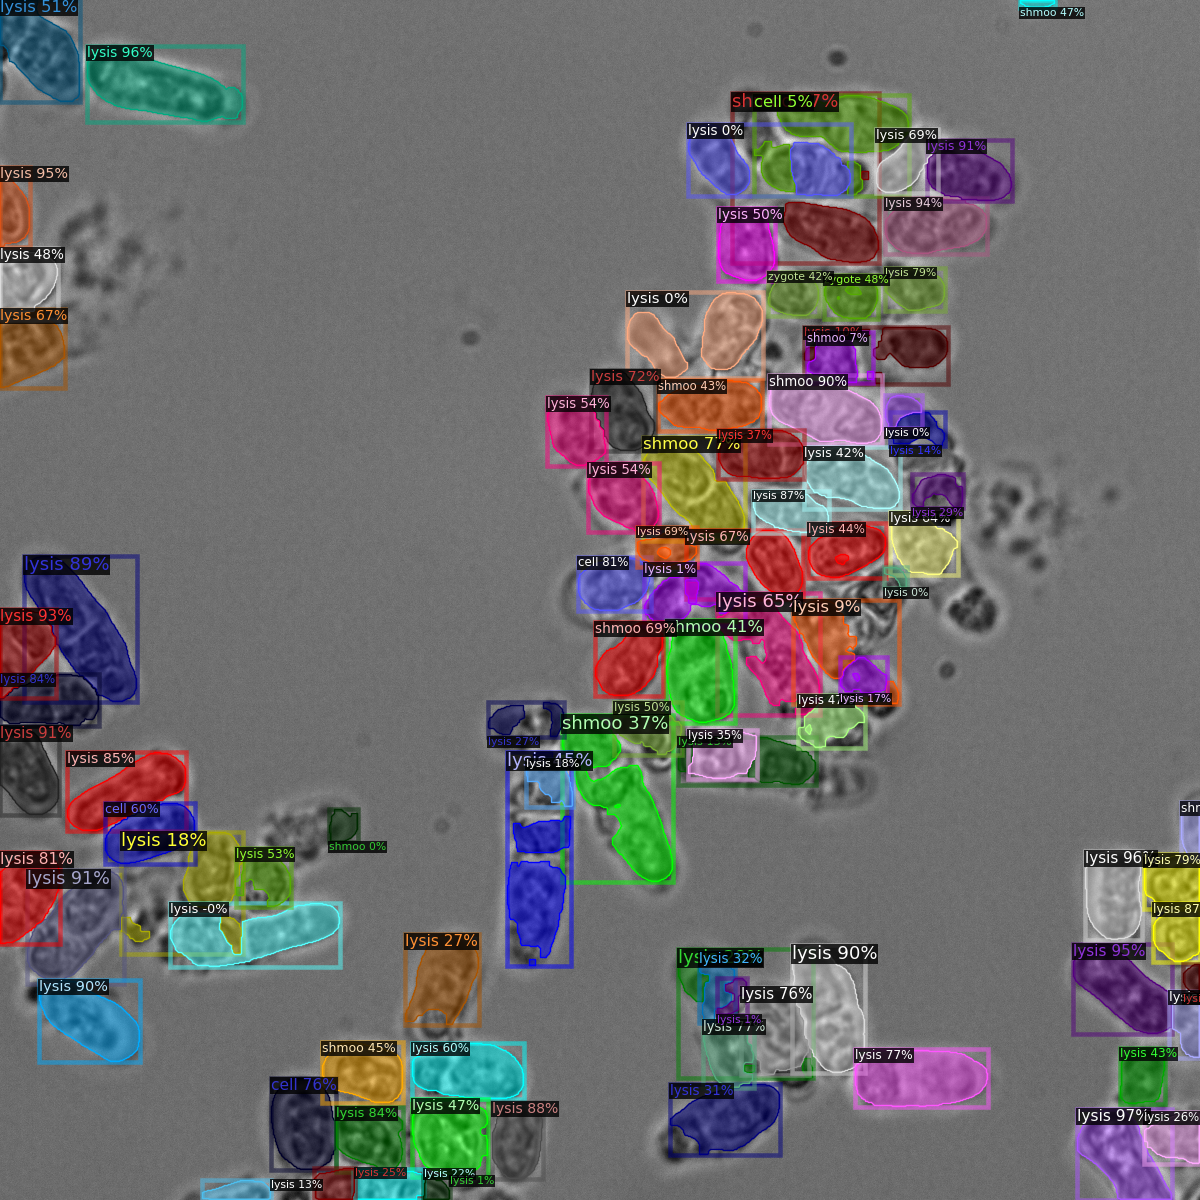

In [21]:
instances = prediction_output["instances"]
v = Visualizer(bigimage[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1)
out = v.draw_instance_predictions(instances.to("cpu"), segments_info)
cv2_imshow(out.get_image()[:, :, ::-1])

In [14]:
from pathlib import Path
from tqdm import trange
movie_path_list = list(Path("./images/").rglob("*x*.tif"))

# movie_path_list = list(Path("/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/").rglob("*.png"))
movie_path_list = [str(x) for x in movie_path_list]
movie_path_list.sort()
movie_path_list

[]

In [11]:
def resize_long_side(image, target):
    """Resize `image` so its longer side equals `target`, keeping aspect ratio."""
    h, w = image.shape[:2]
    scale = target / max(h, w)
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(image, (new_w, new_h), interpolation=interp)


# def resize_panoptic_seg(panoptic_seg, orig_size):
#     """Nearest-neighbor resize a panoptic label map back to `orig_size` (H, W)."""
#     arr = panoptic_seg.to("cpu").numpy()
#     orig_h, orig_w = orig_size
#     resized = cv2.resize(arr.astype(np.int32), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
#     return torch.as_tensor(resized.astype(np.int64))


def resize_panoptic_seg(arr, orig_size):
    """Nearest-neighbor resize a panoptic label map back to `orig_size` (H, W)."""
    # arr = panoptic_seg.to("cpu").numpy()
    orig_h, orig_w = orig_size
    resized = cv2.resize(arr.astype(np.int32), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    return torch.as_tensor(resized.astype(np.int64))


infer_size = 1024

In [ ]:
movie_path = movie_path_list[0]
movie = imread(movie_path)
print(movie.shape)

In [ ]:
plt.imshow(movie[0])

In [59]:
!pwd

/home/liwa/data/PytrochDeepyeast


In [60]:
stem = Path(movie_path).stem

In [70]:
for i in trange(0, len(movie_path_list)):
    # try:
        movie_path = movie_path_list[i]
        movie = imread(movie_path)
        # movie = convert_to_rgb(movie)
        print(movie.shape)
        segment_movie = np.zeros((movie.shape[0],movie.shape[1]), dtype=np.uint16)
        image = convert_to_rgb(movie)

        orig_size = image.shape[:2]
        if infer_size and max(orig_size) > infer_size:
            infer_image = resize_long_side(image, infer_size)
        else:
            infer_image = image         
        prediction_output = predictor(infer_image)
        segment_movie = segment_post_process(prediction_output, ins_threshold=0.0, seg_threshold=0.0, remove_border=True, area_threshold=20)
        # panoptic_seg, segments_info = prediction_output["panoptic_seg"]
        # segment_movie = panoptic_seg.to("cpu").numpy()
        if infer_image.shape[:2] != orig_size:
            segment_movie = resize_panoptic_seg(segment_movie, orig_size)
        stem = Path(movie_path).stem#.split("_")[0]
        imsave("./images/"+stem+"_mask.png", segment_movie.to("cpu").numpy().astype(np.uint16), check_contrast=False)
        del movie, segment_movie
    # except Exception as e:
    #     print(i, "Error occurred:", e)
    #     continue

  0%|                                                                                                                                                                                 | 0/3 [00:00<?, ?it/s]

(2048, 2048)


 33%|████████████████████████████████████████████████████████▎                                                                                                                | 1/3 [00:05<00:11,  5.97s/it]

(2048, 2048)


 67%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋                                                        | 2/3 [00:11<00:05,  5.91s/it]

(2048, 2048)


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:17<00:00,  5.91s/it]


In [34]:
# for movies

In [14]:
from pathlib import Path
from tqdm import trange
movie_path_list = list(Path("./images/").rglob("*.tif"))

# movie_path_list = list(Path("/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/").rglob("*.png"))
movie_path_list = [str(x) for x in movie_path_list]
movie_path_list.sort()
movie_path_list

['images/3_crop_001_002_ROI01_0002-0482-0130_rigid.tif',
 'images/3_crop_002_002_ROI01_0002-0218-0706_rigid.tif',
 'images/4_crop_001_001_rigid_ROI01_0002-0478-0918_rigid.tif']

In [15]:
for i in range(0, len(movie_path_list)):
    try:
        movie_path = movie_path_list[i]
        movie = imread(movie_path)[:,:,:,0]
        print(movie.shape)
        segment_movie = np.zeros(movie.shape, dtype=np.uint16)
                                 
        for f in trange(0, movie.shape[0]):
            image = movie[f]
            image = convert_to_rgb(image)
            prediction_output = predictor(image)
            segment_movie[f] = segment_post_process(prediction_output,
                                                    ins_threshold=0.0,
                                                    seg_threshold=0.0,
                                                    remove_border=True,
                                                    area_threshold=500)
            # panoptic_seg, segments_info = prediction_output["panoptic_seg"]
            # segment_movie = panoptic_seg.to("cpu").numpy()
            stem = Path(movie_path).stem#.split("_")[0]
        imsave("./images/"+stem+"_mask.tif", segment_movie, check_contrast=False)
        del movie, segment_movie
    except Exception as e:
        print(i, "Error occurred:", e)
        continue

(325, 204, 204)


100%|█████████████████████████████████████████| 325/325 [00:19<00:00, 16.52it/s]


(325, 219, 219)


100%|█████████████████████████████████████████| 325/325 [00:22<00:00, 14.56it/s]


(325, 220, 220)


100%|█████████████████████████████████████████| 325/325 [00:17<00:00, 18.58it/s]


In [36]:
movie.shape

(145, 675, 3)